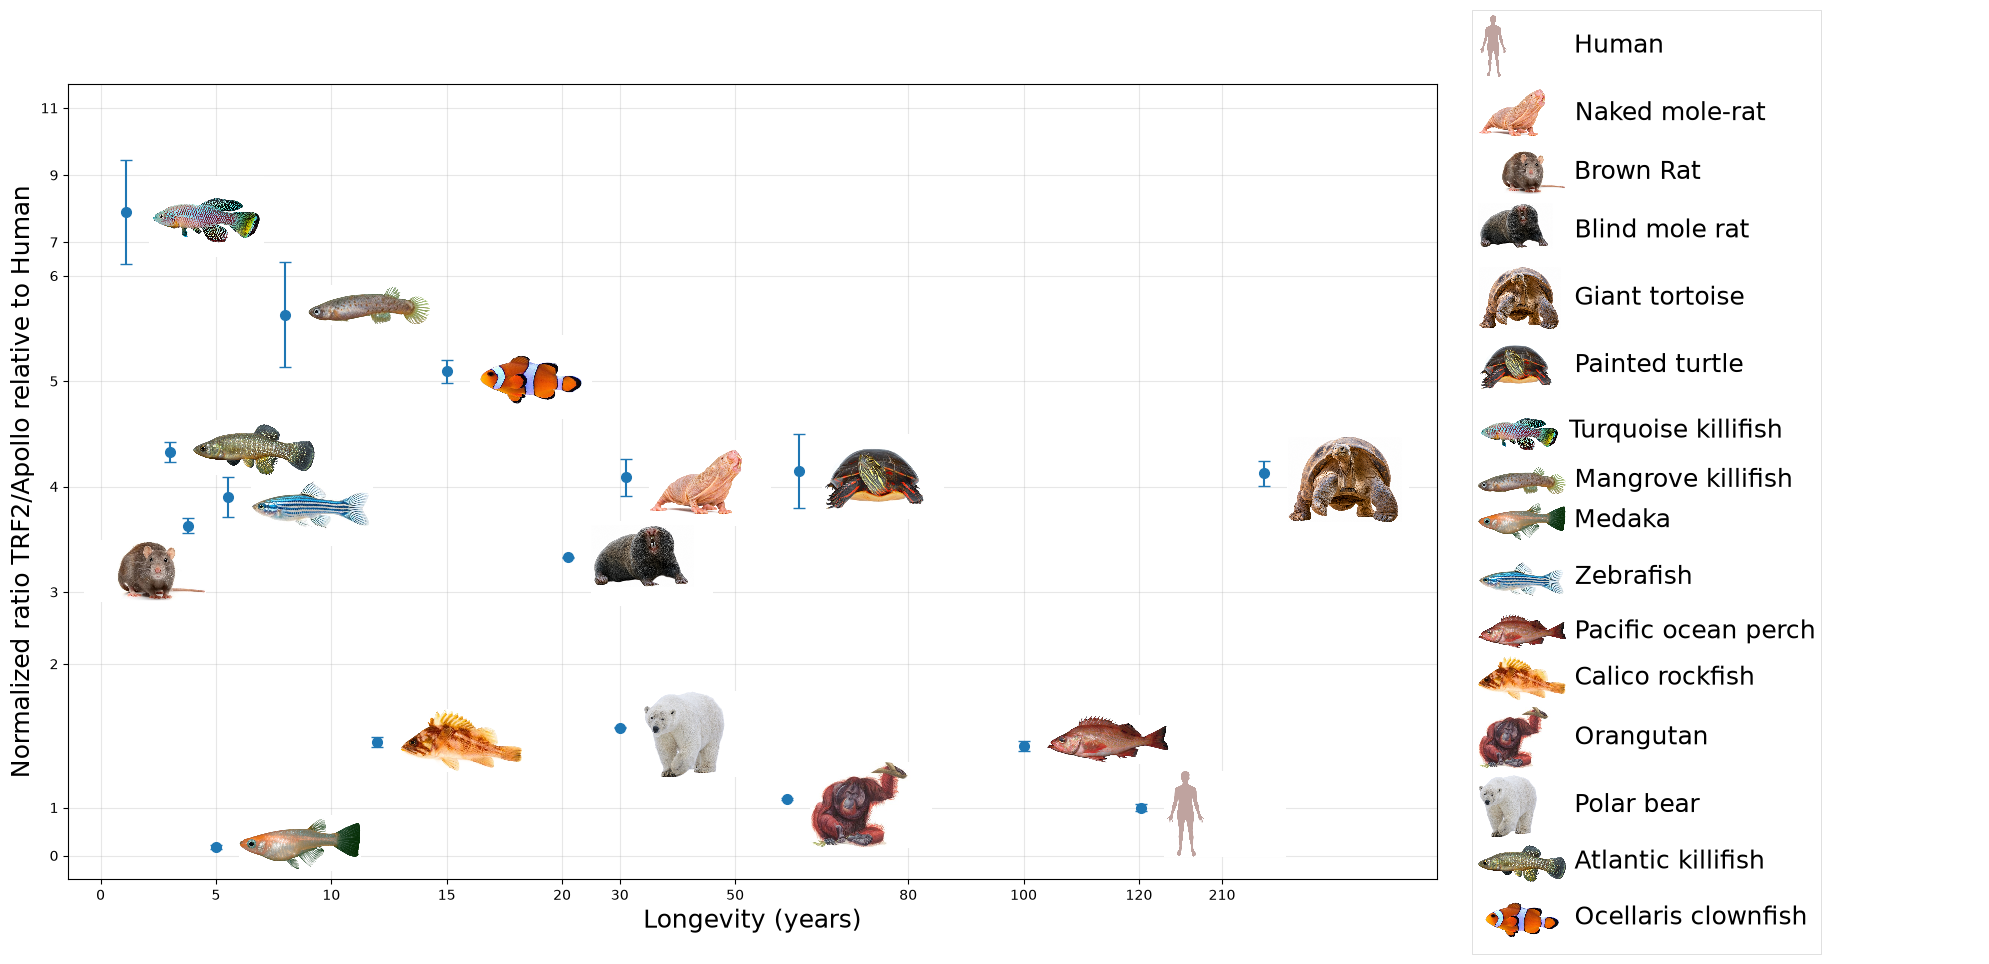

In [9]:

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.offsetbox import OffsetImage, AnnotationBbox, TextArea, HPacker, VPacker, AnchoredOffsetbox
from matplotlib.gridspec import GridSpec
import os

# -----------------------------
# Data
# -----------------------------
species = [
    'Human',
    'Naked mole-rat',
    'Brown Rat',
    'Blind mole rat',
    'Giant tortoise',
    'Painted turtle',
    'Turquoise killifish',
    'Mangrove killifish',
    'Medaka',
    'Zebrafish',
    'Pacific ocean perch',
    'Calico rockfish',
    'Orangutan',
    'Polar bear',
    'Atlantic killifish',
    'Ocellaris clownfish'
]

longevity = [122.5, 31, 3.8, 21,255, 61, 1.1, 8, 5, 5.5, 100, 12, 59, 30, 3, 15]
average = [1, 4.0873202528942, 3.63041252999901,3.32910254979726, 4.125052211, 4.148217735, 7.905123916, 5.628076935, 0.174048197, 3.903317492, 1.426002168, 1.45629683, 1.06172391869141, 1.556175168, 4.326899296, 5.092194419]
sd = [0.13955531501634, 0.772611733, 0.29473447493327, 0.0296497358754351,0.527604161, 1.530780283, 2.180656653, 2.188845708, 0.074466068, 0.8319564, 0.213485868, 0.196739328, 0.037165991086581, 0.033190489, 0.426940825, 0.482105254]

df = pd.DataFrame({
    'Species': species,
    'Longevity': longevity,
    'Average': average,
    'Sd': sd
})

# -----------------------------
# Image map
# -----------------------------
img_map = {
    'Human': 'Hs.png',
    'Naked mole-rat': 'Hg.png',
    'Brown Rat': 'Rn.png',
    'Blind mole rat':'Ng.png',
    'Giant tortoise': 'Ca.png',
    'Painted turtle': 'Cp.png',
    'Turquoise killifish': 'Nf.png',
    'Mangrove killifish': 'Km.png',
    'Medaka': 'OL.png',
    'Zebrafish': 'Dr.png',
    'Pacific ocean perch': 'Sa.png',
    'Calico rockfish': 'Sd.png',
    'Orangutan': 'PP.png',
    'Polar bear': 'Um.png',
    'Atlantic killifish': 'Fh.png',
    'Ocellaris clownfish': 'AO.png',
}

# -----------------------------
# Axis transform
# -----------------------------
def x_transform(x):
    if x <= 20:
        return x * 2.0
    elif x <= 120:
        return 40 + (x - 20) * 0.5
    else:
        return 90 + (x - 120) * 0.08

def y_transform(y):
    if y <= 1:
        return y
    elif y <= 2:
        return 1 + (y - 1) * 3.0
    elif y <= 3:
        return 4.0 + (y - 2) * 1.5
    elif y <= 6:
        return 5.5 + (y - 3) * 2.2
    else:
        return 12.1 + (y - 6) * 0.7

x_plot = df['Longevity'].apply(x_transform)
y_plot = df['Average'].apply(y_transform)

# -----------------------------
# Custom image position
# Brown Rat / Rn.png moved left
# -----------------------------
default_shift = (2.0, 0.5)

custom_shift = {
    'Brown Rat': (-9.0, -0.5),       # Rn.png sang trái
    # Có thể thêm loài khác ở đây nếu muốn chỉnh riêng
    # 'Naked mole-rat': (2.0, 0.8),
}

# -----------------------------
# Figure and layout
# -----------------------------
fig = plt.figure(figsize=(20, 10))
gs = GridSpec(1, 2, width_ratios=[3.2, 1.2], figure=fig)

ax = fig.add_subplot(gs[0, 0])
ax_tbl = fig.add_subplot(gs[0, 1])

# -----------------------------
# Scatter + error bars
# -----------------------------
ax.errorbar(
    x_plot,
    y_plot,
    yerr=df['Sd'] * 0.5,
    fmt='o',
    capsize=4,
    alpha=1.0,
    color='tab:blue',
    ecolor='tab:blue',
    elinewidth=1.5,
    markersize=7
)

# -----------------------------
# Add species images
# -----------------------------
for xi, yi, (_, row) in zip(x_plot, y_plot, df.iterrows()):
    species_name = row['Species']
    img_file = img_map.get(species_name)
    dx, dy = custom_shift.get(species_name, default_shift)

    try:
        img = Image.open(img_file).convert('RGBA')
        im = OffsetImage(img, zoom=0.09)

        ab = AnnotationBbox(
            im,
            (xi + dx, yi + dy),
            frameon=False,
            box_alignment=(0, 0.85)
        )
        ax.add_artist(ab)

    except Exception:
        ax.annotate(
            species_name,
            (xi + dx, yi + dy),
            fontsize=12,
            va='center'
        )

# -----------------------------
# Custom ticks
# -----------------------------
xticks = [0, 5, 10, 15, 20, 30, 50, 80, 100, 120, 210]
ax.set_xticks([x_transform(v) for v in xticks])
ax.set_xticklabels([str(v) for v in xticks])

yticks = [0, 1, 2, 3, 4, 5, 6, 7, 9, 11]
ax.set_yticks([y_transform(v) for v in yticks])
ax.set_yticklabels([str(v) for v in yticks])

# -----------------------------
# Axis limits and labels
# -----------------------------
ax.set_xlim(x_transform(min(longevity)) - 5, x_transform(max(longevity)) + 15)
ax.set_ylim(y_transform(0) - 0.5, y_transform(11) + 0.5)

ax.set_xlabel('Longevity (years)', fontsize=18)
ax.set_ylabel('Normalized ratio TRF2/Apollo relative to Human', fontsize=18)
ax.set_title('', fontsize=20)
ax.grid(True, alpha=0.3)

# -----------------------------
# Legend-like species panel
# -----------------------------
ax_tbl.axis('off')
rows = []

for sp in species:
    img_file = img_map[sp]

    if os.path.exists(img_file):
        img = Image.open(img_file).convert('RGBA')
        icon_part = OffsetImage(img, zoom=0.065)
    else:
        icon_part = TextArea('■', textprops=dict(size=12))

    txt = TextArea(sp, textprops=dict(size=18))
    rowbox = HPacker(children=[icon_part, txt], align='center', pad=0, sep=6)
    rows.append(rowbox)

legend_box = VPacker(children=rows, align='left', pad=0, sep=4)

anchored = AnchoredOffsetbox(
    loc='center left',
    child=legend_box,
    pad=0.4,
    frameon=True,
    bbox_to_anchor=(0.0, 0.5),
    bbox_transform=ax_tbl.transAxes,
    borderpad=0.4
)

anchored.patch.set_facecolor('white')
anchored.patch.set_edgecolor('#d3d3d3')
anchored.patch.set_linewidth(0.5)

ax_tbl.add_artist(anchored)

plt.tight_layout()
plt.show()
fig.savefig("scatter plot homologous interaction", dpi=600, bbox_inches="tight", pad_inches=0.1)


In [8]:
import pandas as pd

species = [
    'Human',
    'Naked mole-rat',
    'Brown Rat',
    'Blind mole rat',
    'Giant tortoise',
    'Painted turtle',
    'Turquoise killifish',
    'Mangrove killifish',
    'Medaka',
    'Zebrafish',
    'Pacific ocean perch',
    'Calico rockfish',
    'Orangutan',
    'Polar bear',
    'Atlantic killifish',
    'Ocellaris clownfish'
]

longevity = [122.5, 31, 3.8, 21,255, 61, 1.1, 8, 5, 5.5, 100, 12, 59, 30, 3, 15]
average = [1, 4.0873202528942, 3.63041252999901,3.32910254979726, 4.125052211, 4.148217735, 7.905123916, 5.628076935, 0.174048197, 3.903317492, 1.426002168, 1.45629683, 1.06172391869141, 1.556175168, 4.326899296, 5.092194419]
sd = [0.13955531501634, 0.772611733, 0.29473447493327, 0.0296497358754351,0.527604161, 1.530780283, 2.180656653, 2.188845708, 0.074466068, 0.8319564, 0.213485868, 0.196739328, 0.037165991086581, 0.033190489, 0.426940825, 0.482105254]

def fmt(x):
    return f"{x:.2f}".replace('.', ',')

df = pd.DataFrame({
    'Species': species,
    'Longevity': [str(x).replace('.', ',') for x in longevity],
    'Average ± Sd': [f"{fmt(a)} ± {fmt(s)}" for a, s in zip(average, sd)]
})

df

,Species,Longevity,Average ± Sd
0,Human,"122,5","1,00 ± 0,14"
1,Naked mole-rat,31,"4,09 ± 0,77"
2,Brown Rat,"3,8","3,63 ± 0,29"
3,Blind mole rat,21,"3,33 ± 0,03"
4,Giant tortoise,255,"4,13 ± 0,53"
5,Painted turtle,61,"4,15 ± 1,53"
6,Turquoise killifish,"1,1","7,91 ± 2,18"
7,Mangrove killifish,8,"5,63 ± 2,19"
8,Medaka,5,"0,17 ± 0,07"
9,Zebrafish,"5,5","3,90 ± 0,83"


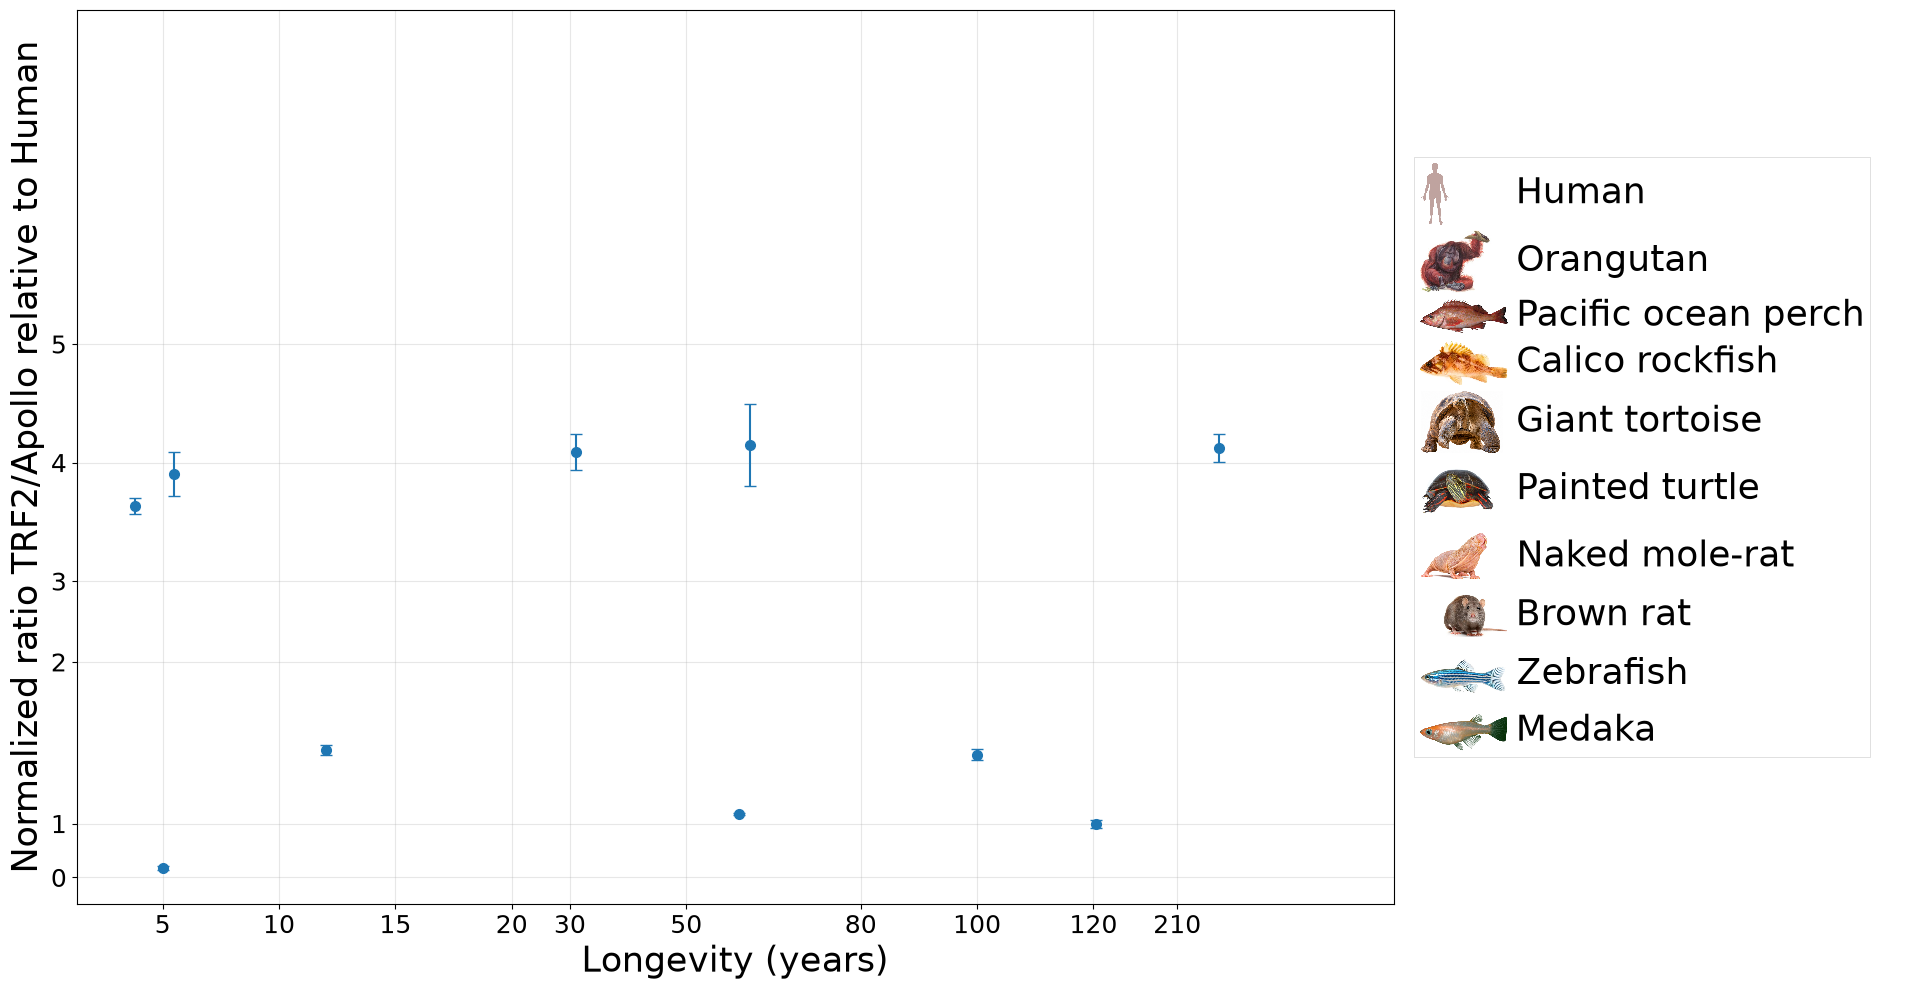

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.offsetbox import OffsetImage, AnnotationBbox, TextArea, HPacker, VPacker, AnchoredOffsetbox
from matplotlib.gridspec import GridSpec
import os

# -----------------------------
# Data
# -----------------------------
species = [
    'Human',
    'Orangutan',
    'Pacific ocean perch',
    'Calico rockfish',
    'Giant tortoise',
    'Painted turtle',
    'Naked mole-rat',
    'Brown rat',
    'Zebrafish',
    'Medaka'

]

longevity = [122.5, 59, 100, 12, 255, 61, 31, 3.8,5.5,5]
average = [1, 1.06172391869141, 1.42600217, 1.45629683, 4.12505221, 4.14821774, 4.0873202528942, 3.63041252999901,3.903317492,0.174048197]
sd = [0.147, 0.037165991086581, 0.213, 0.197, 0.528, 1.531, 0.660716064166307, 0.29473447493327,0.8319564,  0.074466068]

df = pd.DataFrame({
    'Species': species,
    'Longevity': longevity,
    'Average': average,
    'Sd': sd
})

# -----------------------------
# Image map
# -----------------------------
img_map = {
    'Human': 'Hs.png',
    'Naked mole-rat': 'Hg.png',
    'Brown rat': 'Rn.png',
    'Giant tortoise': 'Ca.png',
    'Painted turtle': 'Cp.png',
    'Turquoise killifish': 'Nf.png',
    'Mangrove killifish': 'Km.png',
    'Medaka': 'OL.png',
    'Zebrafish': 'Dr.png',
    'Pacific ocean perch': 'Sa.png',
    'Calico rockfish': 'Sd.png',
    'Orangutan': 'PP.png',
    'Polar bear': 'Um.png',
    'Atlantic killifish': 'Fh.png',
    'Ocellaris clownfish': 'AO.png',
}

# -----------------------------
# Axis transform
# -----------------------------
def x_transform(x):
    if x <= 20:
        return x * 2.0
    elif x <= 120:
        return 40 + (x - 20) * 0.5
    else:
        return 90 + (x - 120) * 0.08

def y_transform(y):
    if y <= 1:
        return y
    elif y <= 2:
        return 1 + (y - 1) * 3.0
    elif y <= 3:
        return 4.0 + (y - 2) * 1.5
    elif y <= 6:
        return 5.5 + (y - 3) * 2.2
    else:
        return 12.1 + (y - 6) * 0.7

x_plot = df['Longevity'].apply(x_transform)
y_plot = df['Average'].apply(y_transform)

# -----------------------------
# Custom image position
# -----------------------------
default_shift = (2.0, 0.5)
custom_shift = {
    'Brown rat': (0.0, -0.5),
}

# -----------------------------
# Figure and layout
# -----------------------------
fig = plt.figure(figsize=(20, 10))
gs = GridSpec(1, 2, width_ratios=[3.2, 1.2], figure=fig)

ax = fig.add_subplot(gs[0, 0])
ax_tbl = fig.add_subplot(gs[0, 1])

# -----------------------------
# Scatter + error bars
# -----------------------------
ax.errorbar(
    x_plot,
    y_plot,
    yerr=df['Sd'] * 0.5,
    fmt='o',
    capsize=4,
    alpha=1.0,
    color='tab:blue',
    ecolor='tab:blue',
    elinewidth=1.5,
    markersize=7
)



# -----------------------------
# Custom ticks
# -----------------------------
xticks = [0, 5, 10, 15, 20, 30, 50, 80, 100, 120, 210]
ax.set_xticks([x_transform(v) for v in xticks])
ax.set_xticklabels([str(v) for v in xticks], fontsize=18)

yticks = [0, 1, 2, 3, 4, 5,6]
ax.set_yticks([y_transform(v) for v in yticks])
ax.set_yticklabels([str(v) for v in yticks], fontsize=18)

# -----------------------------
# Axis limits and labels
# -----------------------------
ax.set_xlim(x_transform(min(longevity)) - 5, x_transform(max(longevity)) + 15)
ax.set_ylim(y_transform(0) - 0.5, y_transform(11) + 0.5)

ax.set_xlabel('Longevity (years)', fontsize=25)
ax.set_ylabel('Normalized ratio TRF2/Apollo relative to Human', fontsize=25)
ax.set_title('', fontsize=20)
ax.grid(True, alpha=0.3)

# -----------------------------
# Legend-like species panel
# -----------------------------
ax_tbl.axis('off')
rows = []

for sp in species:
    img_file = img_map.get(sp)
    if img_file and os.path.exists(img_file):
        img = Image.open(img_file).convert('RGBA')
        icon_part = OffsetImage(img, zoom=0.065)
    else:
        icon_part = TextArea('■', textprops=dict(size=15))

    txt = TextArea(sp, textprops=dict(size=26))
    rowbox = HPacker(children=[icon_part, txt], align='center', pad=0, sep=6)
    rows.append(rowbox)

legend_box = VPacker(children=rows, align='left', pad=0, sep=4)

anchored = AnchoredOffsetbox(
    loc='center left',
    child=legend_box,
    pad=0.4,
    frameon=True,
    bbox_to_anchor=(0.0, 0.5),
    bbox_transform=ax_tbl.transAxes,
    borderpad=0.4
)

anchored.patch.set_facecolor('white')
anchored.patch.set_edgecolor('#d3d3d3')
anchored.patch.set_linewidth(0.5)

ax_tbl.add_artist(anchored)

plt.tight_layout()
plt.show()
fig.savefig("confirmed no related to longevity", dpi=600, bbox_inches="tight", pad_inches=0.1)


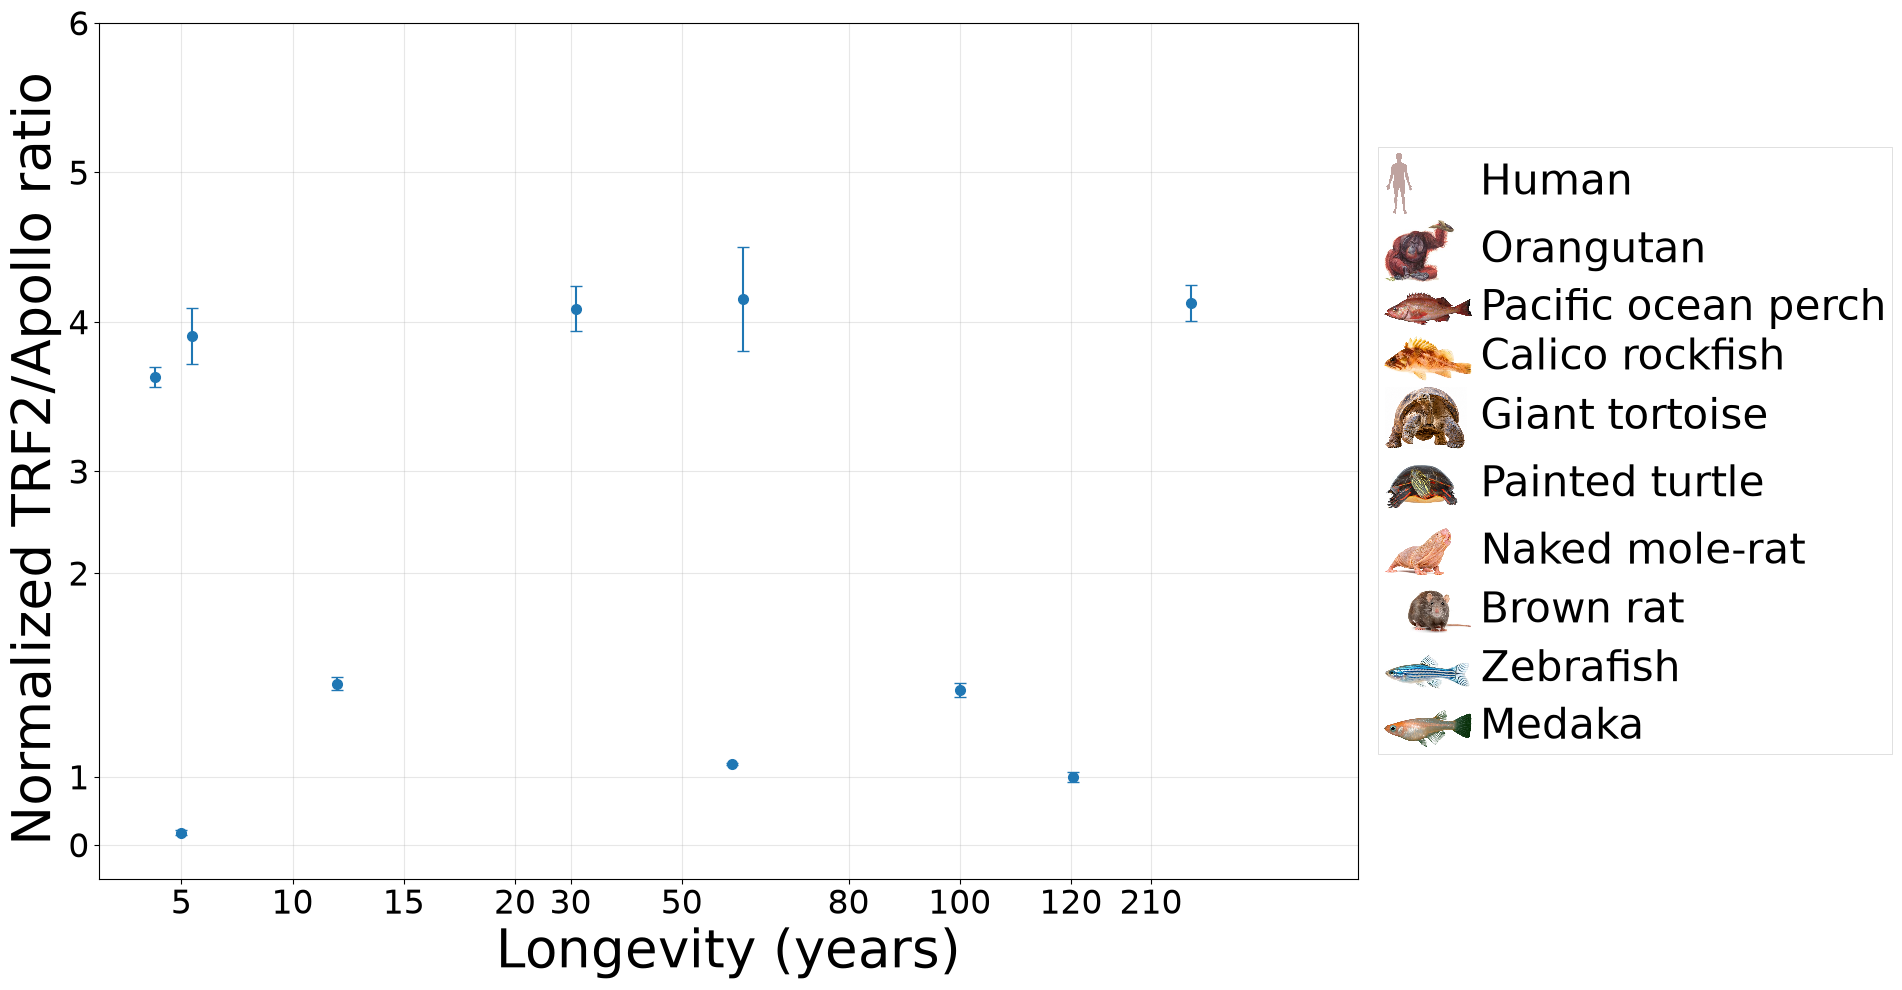

In [14]:

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.offsetbox import (
    OffsetImage,
    AnnotationBbox,
    TextArea,
    HPacker,
    VPacker,
    AnchoredOffsetbox
)
from matplotlib.gridspec import GridSpec
import os

# -----------------------------
# Data
# -----------------------------
species = [
    'Human',
    'Orangutan',
    'Pacific ocean perch',
    'Calico rockfish',
    'Giant tortoise',
    'Painted turtle',
    'Naked mole-rat',
    'Brown rat',
    'Zebrafish',
    'Medaka'
]

longevity = [
    122.5,
    59,
    100,
    12,
    255,
    61,
    31,
    3.8,
    5.5,
    5
]

average = [
    1,
    1.06172391869141,
    1.42600217,
    1.45629683,
    4.12505221,
    4.14821774,
    4.0873202528942,
    3.63041252999901,
    3.903317492,
    0.174048197
]

sd = [
    0.147,
    0.037165991086581,
    0.213,
    0.197,
    0.528,
    1.531,
    0.660716064166307,
    0.29473447493327,
    0.8319564,
    0.074466068
]

df = pd.DataFrame({
    'Species': species,
    'Longevity': longevity,
    'Average': average,
    'Sd': sd
})

# -----------------------------
# Image map
# -----------------------------
img_map = {
    'Human': 'Hs.png',
    'Naked mole-rat': 'Hg.png',
    'Brown rat': 'Rn.png',
    'Giant tortoise': 'Ca.png',
    'Painted turtle': 'Cp.png',
    'Turquoise killifish': 'Nf.png',
    'Mangrove killifish': 'Km.png',
    'Medaka': 'OL.png',
    'Zebrafish': 'Dr.png',
    'Pacific ocean perch': 'Sa.png',
    'Calico rockfish': 'Sd.png',
    'Orangutan': 'PP.png',
    'Polar bear': 'Um.png',
    'Atlantic killifish': 'Fh.png',
    'Ocellaris clownfish': 'AO.png',
}

# -----------------------------
# Axis transform
# -----------------------------
def x_transform(x):
    if x <= 20:
        return x * 2.0
    elif x <= 120:
        return 40 + (x - 20) * 0.5
    else:
        return 90 + (x - 120) * 0.08


def y_transform(y):
    if y <= 1:
        return y
    elif y <= 2:
        return 1 + (y - 1) * 3.0
    elif y <= 3:
        return 4.0 + (y - 2) * 1.5
    elif y <= 6:
        return 5.5 + (y - 3) * 2.2
    else:
        return 12.1 + (y - 6) * 0.7


x_plot = df['Longevity'].apply(x_transform)
y_plot = df['Average'].apply(y_transform)

# -----------------------------
# Custom image position
# -----------------------------
default_shift = (2.0, 0.5)

custom_shift = {
    'Brown rat': (0.0, -0.5),
}

# -----------------------------
# Figure and layout
# -----------------------------
fig = plt.figure(figsize=(20, 10))

gs = GridSpec(
    1,
    2,
    width_ratios=[3.2, 1.2],
    figure=fig
)

ax = fig.add_subplot(gs[0, 0])
ax_tbl = fig.add_subplot(gs[0, 1])

# -----------------------------
# Scatter + error bars
# -----------------------------
ax.errorbar(
    x_plot,
    y_plot,
    yerr=df['Sd'] * 0.5,
    fmt='o',
    capsize=4,
    alpha=1.0,
    color='tab:blue',
    ecolor='tab:blue',
    elinewidth=1.5,
    markersize=7
)

# -----------------------------
# Custom ticks
# -----------------------------
xticks = [
    0,
    5,
    10,
    15,
    20,
    30,
    50,
    80,
    100,
    120,
    210
]

ax.set_xticks(
    [x_transform(v) for v in xticks]
)

ax.set_xticklabels(
    [str(v) for v in xticks],
    fontsize=24
)

yticks = [
    0,
    1,
    2,
    3,
    4,
    5,
    6
]

ax.set_yticks(
    [y_transform(v) for v in yticks]
)

ax.set_yticklabels(
    [str(v) for v in yticks],
    fontsize=24
)

# -----------------------------
# Axis limits and labels
# -----------------------------

# X-axis
ax.set_xlim(
    x_transform(min(longevity)) - 5,
    x_transform(max(longevity)) + 15
)

# Y-axis:
# Stop exactly at the transformed value of 6
ax.set_ylim(
    y_transform(0) - 0.5,
    y_transform(6)
)

ax.set_xlabel(
    'Longevity (years)',
    fontsize=38
)

ax.set_ylabel(
    'Normalized TRF2/Apollo ratio ',
    fontsize=38
)

ax.set_title(
    '',
    fontsize=28
)

ax.grid(
    True,
    alpha=0.3
)

# -----------------------------
# Legend-like species panel
# -----------------------------
ax_tbl.axis('off')

rows = []

for sp in species:

    img_file = img_map.get(sp)

    if img_file and os.path.exists(img_file):

        img = Image.open(img_file).convert('RGBA')

        icon_part = OffsetImage(
            img,
            zoom=0.065
        )

    else:

        icon_part = TextArea(
            '■',
            textprops=dict(size=15)
        )

    txt = TextArea(
        sp,
        textprops=dict(size=30)
    )

    rowbox = HPacker(
        children=[
            icon_part,
            txt
        ],
        align='center',
        pad=0,
        sep=6
    )

    rows.append(rowbox)

legend_box = VPacker(
    children=rows,
    align='left',
    pad=0,
    sep=4
)

anchored = AnchoredOffsetbox(
    loc='center left',
    child=legend_box,
    pad=0.4,
    frameon=True,
    bbox_to_anchor=(0.0, 0.5),
    bbox_transform=ax_tbl.transAxes,
    borderpad=0.4
)

anchored.patch.set_facecolor('white')
anchored.patch.set_edgecolor('#d3d3d3')
anchored.patch.set_linewidth(0.5)

ax_tbl.add_artist(anchored)

# -----------------------------
# Layout
# -----------------------------
plt.tight_layout()

# -----------------------------
# Show figure
# -----------------------------
plt.show()

# -----------------------------
# Save figure
# -----------------------------
fig.savefig(
    "confirmed no related to longevity",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.1
)



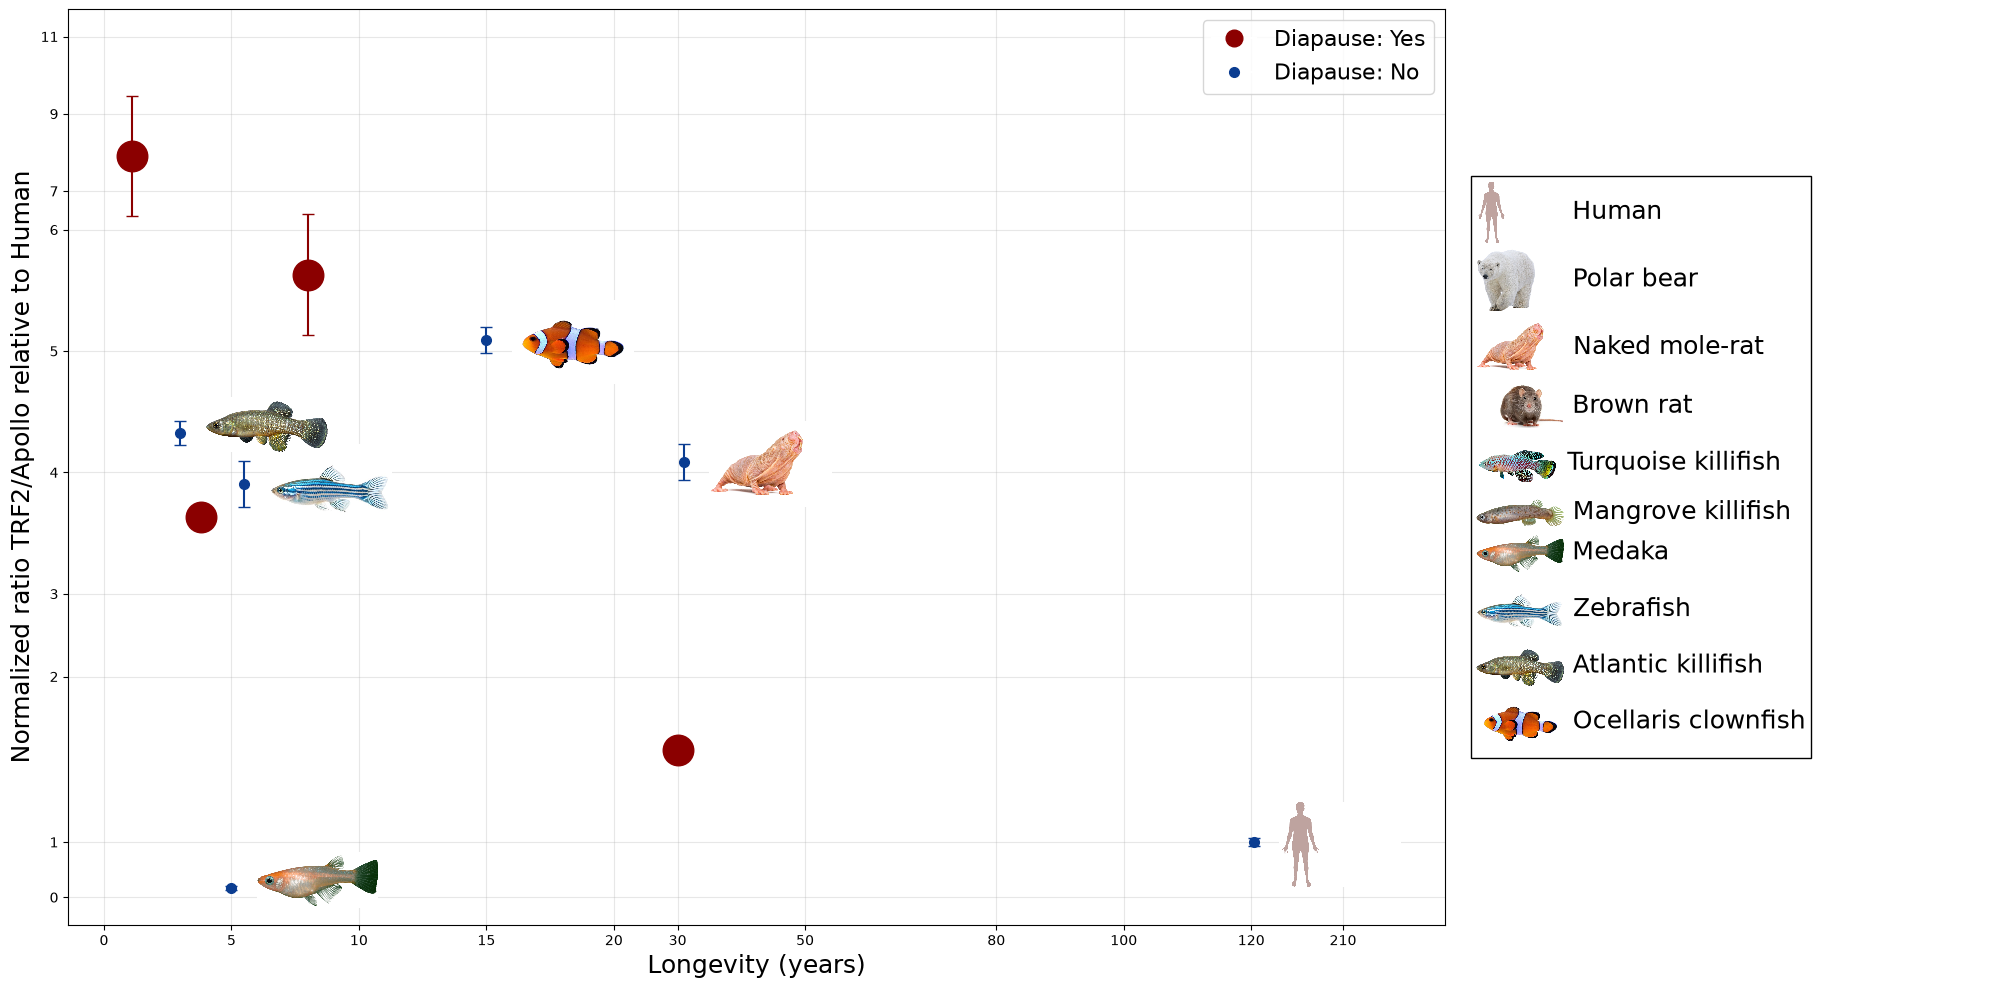

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.offsetbox import (
    OffsetImage, AnnotationBbox,
    TextArea, HPacker, VPacker,
    AnchoredOffsetbox
)
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
import os

# ==========================================================
# Data
# ==========================================================
species = [
    'Human',
    'Polar bear',
    'Naked mole-rat',
    'Brown rat',
    'Turquoise killifish',
    'Mangrove killifish',
    'Medaka',
    'Zebrafish',
    'Atlantic killifish',
    'Ocellaris clownfish'
]

longevity = [122.5, 30, 31, 3.8, 1.1, 8, 5, 5.5, 3, 15]

average = [1, 1.556, 4.0873202528942, 3.63041252999901,
           7.905, 5.628, 0.174,
           3.903, 4.327, 5.092]

sd = [0.147, 0.033, 0.660716064166307, 0.29473447493327,
      2.181, 2.189, 0.074,
      0.832, 0.427, 0.482]

diapause = [
    'no',
    'yes',
    'no',
    'yes',
    'yes',
    'yes',
    'no',
    'no',
    'no',
    'no'
]

df = pd.DataFrame({
    'Species': species,
    'Longevity': longevity,
    'Average': average,
    'Sd': sd,
    'Diapause': diapause
})

# ==========================================================
# Image map
# ==========================================================
img_map = {
    'Human': 'Hs.png',
    'Naked mole-rat': 'Hg.png',
    'Brown rat': 'Rn.png',
    'Turquoise killifish': 'Nf.png',
    'Mangrove killifish': 'Km.png',
    'Medaka': 'OL.png',
    'Zebrafish': 'Dr.png',
    'Polar bear': 'Um.png',
    'Atlantic killifish': 'Fh.png',
    'Ocellaris clownfish': 'AO.png',
}

# ==========================================================
# Colors
# ==========================================================
color_map = {
    "yes": "#8B0000",   # dark red
    "no": "#0B3D91"     # dark blue
}

# ==========================================================
# Axis transform
# ==========================================================
def x_transform(x):
    if x <= 20:
        return x * 2
    elif x <= 120:
        return 40 + (x - 20) * 0.5
    else:
        return 90 + (x - 120) * 0.08


def y_transform(y):
    if y <= 1:
        return y
    elif y <= 2:
        return 1 + (y - 1) * 3
    elif y <= 3:
        return 4 + (y - 2) * 1.5
    elif y <= 6:
        return 5.5 + (y - 3) * 2.2
    else:
        return 12.1 + (y - 6) * 0.7


x_plot = df["Longevity"].apply(x_transform)
y_plot = df["Average"].apply(y_transform)

# ==========================================================
# Image position
# ==========================================================
default_shift = (2.0, 0.5)

custom_shift = {
    "Brown rat": (-7, -0.5)
}

# ==========================================================
# Figure
# ==========================================================
fig = plt.figure(figsize=(20,10))

gs = GridSpec(
    1,
    2,
    width_ratios=[3.2,1.2],
    figure=fig
)

ax = fig.add_subplot(gs[0,0])
ax_tbl = fig.add_subplot(gs[0,1])

# ==========================================================
# Scatter
# ==========================================================
for xi, yi, (_, row) in zip(x_plot, y_plot, df.iterrows()):

    point_color = color_map[row["Diapause"]]

    marker_size = 22 if row["Diapause"]=="yes" else 7

    ax.errorbar(
        xi,
        yi,
        yerr=row["Sd"]*0.5,
        fmt='o',
        color=point_color,
        ecolor=point_color,
        markersize=marker_size,
        capsize=4,
        elinewidth=1.5
    )

# ==========================================================
# Images
# ==========================================================
# ==========================================================
# Images
# ==========================================================

remove_images = {
    'Turquoise killifish',
    'Polar bear',
    'Brown rat',
    'Mangrove killifish'
}

for xi, yi, (_, row) in zip(x_plot, y_plot, df.iterrows()):

    species_name = row["Species"]

    # Skip selected images
    if species_name in remove_images:
        continue

    dx, dy = custom_shift.get(
        species_name,
        default_shift
    )

    img_file = img_map.get(species_name)

    try:
        img = Image.open(img_file).convert("RGBA")

        im = OffsetImage(
            img,
            zoom=0.09
        )

        ab = AnnotationBbox(
            im,
            (xi + dx, yi + dy),
            frameon=False,
            box_alignment=(0,0.85)
        )

        ax.add_artist(ab)

    except Exception:

        ax.annotate(
            species_name,
            (xi+dx, yi+dy),
            fontsize=12
        )

# ==========================================================
# Axis
# ==========================================================
xticks=[0,5,10,15,20,30,50,80,100,120,210]

ax.set_xticks([x_transform(v) for v in xticks])
ax.set_xticklabels([str(v) for v in xticks])

yticks=[0,1,2,3,4,5,6,7,9,11]

ax.set_yticks([y_transform(v) for v in yticks])
ax.set_yticklabels([str(v) for v in yticks])

ax.set_xlim(
    x_transform(min(longevity))-5,
    x_transform(max(longevity))+15
)

ax.set_ylim(
    y_transform(0)-0.5,
    y_transform(11)+0.5
)

ax.set_xlabel(
    "Longevity (years)",
    fontsize=18
)

ax.set_ylabel(
    "Normalized ratio TRF2/Apollo relative to Human",
    fontsize=18
)

ax.grid(alpha=0.3)

# ==========================================================
# Diapause legend
# ==========================================================
legend_elements = [

    Line2D(
        [0],[0],
        marker='o',
        color='w',
        label='Diapause: Yes',
        markerfacecolor=color_map["yes"],
        markeredgecolor=color_map["yes"],
        markersize=12
    ),

    Line2D(
        [0],[0],
        marker='o',
        color='w',
        label='Diapause: No',
        markerfacecolor=color_map["no"],
        markeredgecolor=color_map["no"],
        markersize=7
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper right",
    fontsize=16,
    frameon=True
)

# ==========================================================
# Species panel
# ==========================================================
ax_tbl.axis("off")

rows=[]

for sp in species:

    img_file=img_map.get(sp)

    if img_file and os.path.exists(img_file):

        img=Image.open(img_file).convert("RGBA")

        icon=OffsetImage(
            img,
            zoom=0.065
        )

    else:

        icon=TextArea(
            "■",
            textprops=dict(size=12)
        )

    txt=TextArea(
        sp,
        textprops=dict(size=18)
    )

    rows.append(
        HPacker(
            children=[icon,txt],
            align="center",
            pad=0,
            sep=6
        )
    )

legend_box=VPacker(
    children=rows,
    align="left",
    pad=0,
    sep=4
)

anchored=AnchoredOffsetbox(
    loc="center left",
    child=legend_box,
    frameon=True,
    bbox_to_anchor=(0,0.5),
    bbox_transform=ax_tbl.transAxes
)

ax_tbl.add_artist(anchored)

plt.tight_layout()

plt.savefig(
    "confirmed_no_related_to_diapause.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

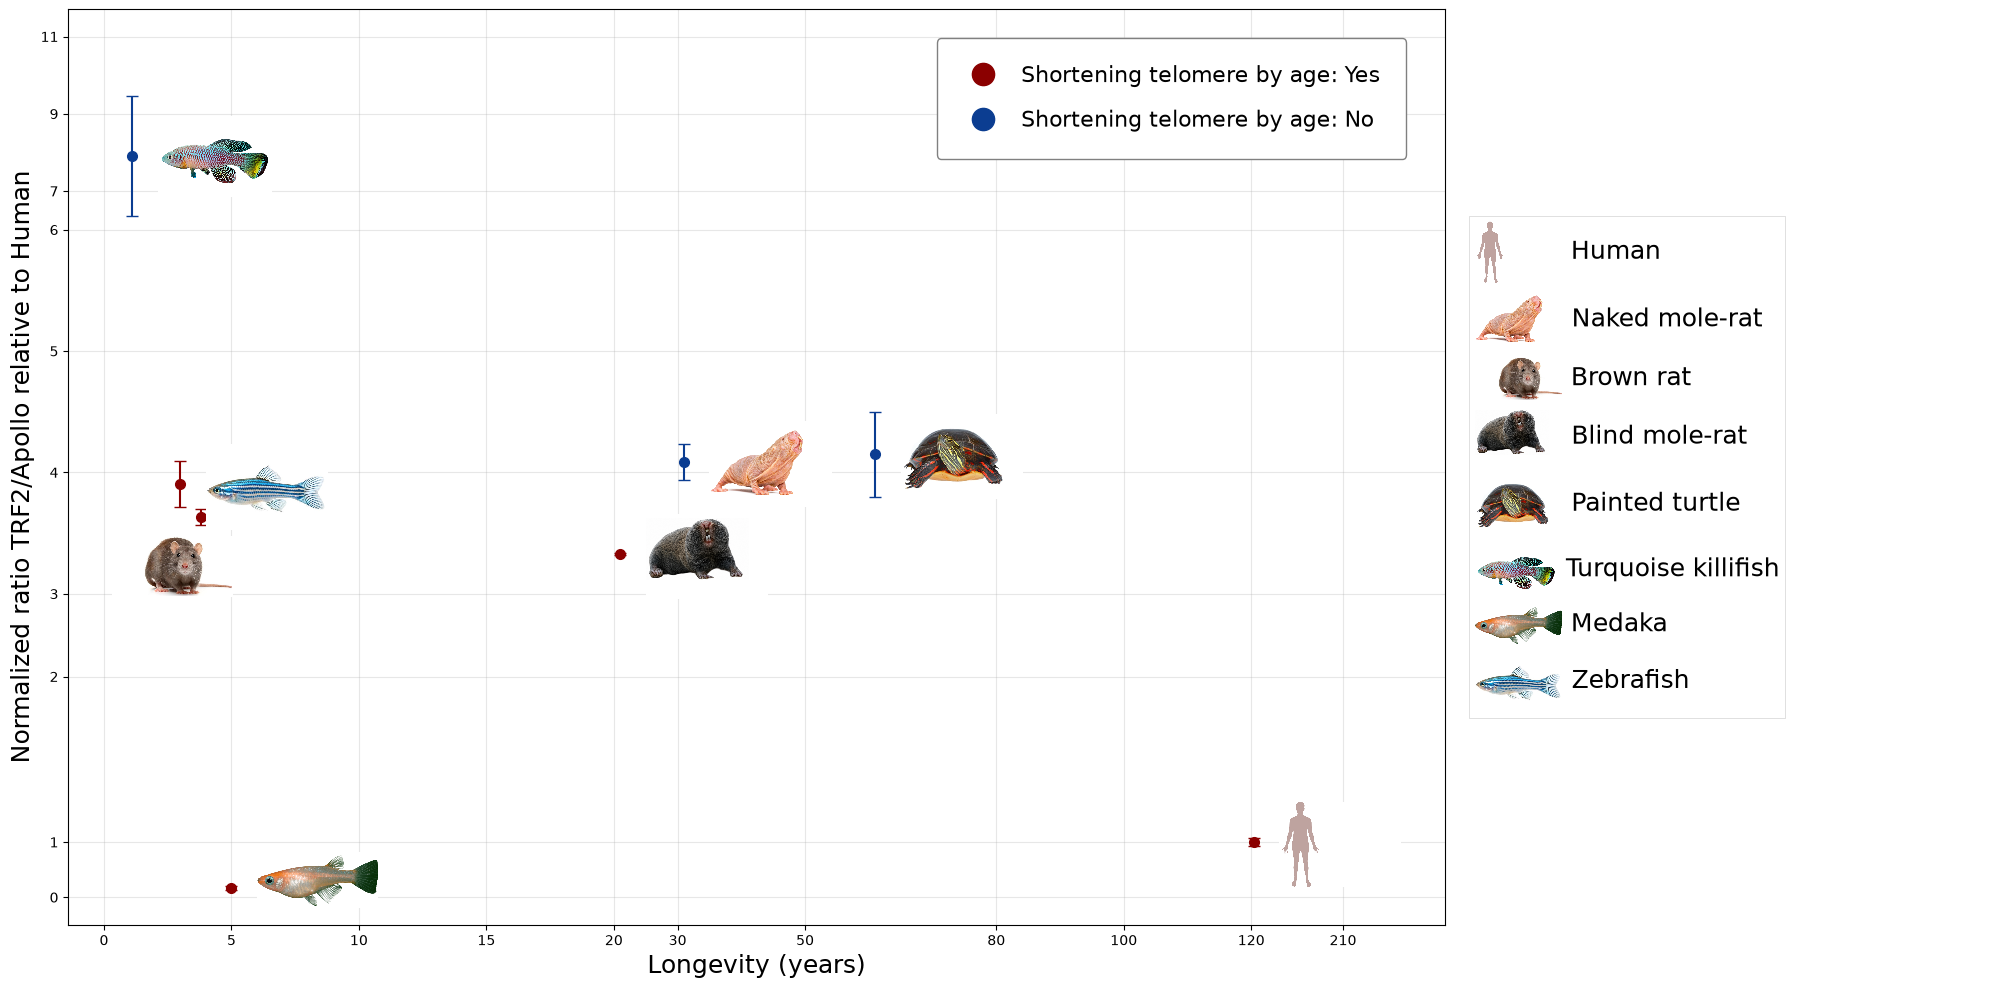

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.offsetbox import OffsetImage, AnnotationBbox, TextArea, HPacker, VPacker, AnchoredOffsetbox
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
import os

# -----------------------------
# Data
# -----------------------------
species = [
    'Human',
    'Naked mole-rat',
    'Brown rat',
    'Blind mole-rat',
    'Painted turtle',
    'Turquoise killifish',
    'Medaka',
    'Zebrafish',

]

longevity = [122.5, 31, 3.8, 21, 61, 1.1, 5, 3]
average = [1, 4.087320253, 3.63041253, 3.32910255,4.148217735, 7.905123916,0.174048197, 3.903317492]
sd = [0.139555315, 0.660716064, 0.294734475, 0.029649736, 1.530780283, 2.180656653, 0.074466068, 0.8319564]

Shorten_telomere = [
    'yes',   # Human
    'no',   # Naked mole-rat
    'yes',  # Brown rat
    'yes',  # Blind mole-rat
    'no',  # Painted turtle
    'no',  # Turquoise killifish
    'yes',   # Medaka
    'yes',   # Zebrafish

]

df = pd.DataFrame({
    'Species': species,
    'Longevity': longevity,
    'Average': average,
    'Sd': sd,
    'Shorten_telomere': Shorten_telomere
})

# -----------------------------
# Image map
# -----------------------------
img_map = {
    'Human': 'Hs.png',
    'Naked mole-rat': 'Hg.png',
    'Brown rat': 'Rn.png',
    'Blind mole-rat': 'Ng.png',
    'Painted turtle': 'Cp.png',
    'Turquoise killifish': 'Nf.png',
    'Medaka': 'OL.png',
    'Zebrafish': 'Dr.png',
}

# -----------------------------
# Color map
# yes = đỏ đậm, no = xanh đậm
# -----------------------------
color_map = {
    'yes': '#8B0000',   # dark red
    'no': '#0B3D91'     # dark blue
}

# -----------------------------
# Axis transform
# -----------------------------
def x_transform(x):
    if x <= 20:
        return x * 2.0
    elif x <= 120:
        return 40 + (x - 20) * 0.5
    else:
        return 90 + (x - 120) * 0.08

def y_transform(y):
    if y <= 1:
        return y
    elif y <= 2:
        return 1 + (y - 1) * 3.0
    elif y <= 3:
        return 4.0 + (y - 2) * 1.5
    elif y <= 6:
        return 5.5 + (y - 3) * 2.2
    else:
        return 12.1 + (y - 6) * 0.7

x_plot = df['Longevity'].apply(x_transform)
y_plot = df['Average'].apply(y_transform)

# -----------------------------
# Custom image position
# -----------------------------
default_shift = (2.0, 0.5)
custom_shift = {
    'Brown rat': (-7.0, -0.5),
}

# -----------------------------
# Figure and layout
# -----------------------------
fig = plt.figure(figsize=(20, 10))
gs = GridSpec(1, 2, width_ratios=[3.2, 1.2], figure=fig)

ax = fig.add_subplot(gs[0, 0])
ax_tbl = fig.add_subplot(gs[0, 1])

# -----------------------------
# Scatter + error bars by diapause
# -----------------------------
for xi, yi, (_, row) in zip(x_plot, y_plot, df.iterrows()):
    point_color = color_map.get(row['Shorten_telomere'], '#000000')

    ax.errorbar(
        xi,
        yi,
        yerr=row['Sd'] * 0.5,
        fmt='o',
        capsize=4,
        alpha=1.0,
        color=point_color,
        ecolor=point_color,
        elinewidth=1.5,
        markersize=7
    )

# -----------------------------
# Add species images
# -----------------------------
for xi, yi, (_, row) in zip(x_plot, y_plot, df.iterrows()):
    species_name = row['Species']
    img_file = img_map.get(species_name)
    dx, dy = custom_shift.get(species_name, default_shift)

    try:
        img = Image.open(img_file).convert('RGBA')
        im = OffsetImage(img, zoom=0.09)
        ab = AnnotationBbox(
            im,
            (xi + dx, yi + dy),
            frameon=False,
            box_alignment=(0, 0.85)
        )
        ax.add_artist(ab)
    except Exception:
        ax.annotate(
            species_name,
            (xi + dx, yi + dy),
            fontsize=12,
            va='center'
        )

# -----------------------------
# Custom ticks
# -----------------------------
xticks = [0, 5, 10, 15, 20, 30, 50, 80, 100, 120, 210]
ax.set_xticks([x_transform(v) for v in xticks])
ax.set_xticklabels([str(v) for v in xticks])

yticks = [0, 1, 2, 3, 4, 5, 6, 7, 9, 11]
ax.set_yticks([y_transform(v) for v in yticks])
ax.set_yticklabels([str(v) for v in yticks])

# -----------------------------
# Axis limits and labels
# -----------------------------
ax.set_xlim(x_transform(min(longevity)) - 5, x_transform(max(longevity)) + 15)
ax.set_ylim(y_transform(0) - 0.5, y_transform(11) + 0.5)

ax.set_xlabel('Longevity (years)', fontsize=18)
ax.set_ylabel('Normalized ratio TRF2/Apollo relative to Human', fontsize=18)
ax.set_title('', fontsize=20)
ax.grid(True, alpha=0.3)

# -----------------------------
# Diapause legend - bigger, upper right
# -----------------------------
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Shortening telomere by age: Yes',
           markerfacecolor=color_map['yes'], markeredgecolor=color_map['yes'], markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Shortening telomere by age: No',
           markerfacecolor=color_map['no'], markeredgecolor=color_map['no'], markersize=10)
]

ax.legend(
    handles=legend_elements,
    loc='upper right',
    bbox_to_anchor=(0.98, 0.98),
    fontsize=16,
    frameon=True,
    facecolor='white',
    edgecolor='gray',
    framealpha=1,
    borderpad=1.2,
    labelspacing=1.0,
    handlelength=1.8,
    handletextpad=0.8,
    markerscale=1.6
)

# -----------------------------
# Legend-like species panel
# -----------------------------
ax_tbl.axis('off')
rows = []

for sp in species:
    img_file = img_map.get(sp)
    if img_file and os.path.exists(img_file):
        img = Image.open(img_file).convert('RGBA')
        icon_part = OffsetImage(img, zoom=0.065)
    else:
        icon_part = TextArea('■', textprops=dict(size=12))

    txt = TextArea(sp, textprops=dict(size=18))
    rowbox = HPacker(children=[icon_part, txt], align='center', pad=0, sep=6)
    rows.append(rowbox)

legend_box = VPacker(children=rows, align='left', pad=0, sep=4)

anchored = AnchoredOffsetbox(
    loc='center left',
    child=legend_box,
    pad=0.4,
    frameon=True,
    bbox_to_anchor=(0.0, 0.5),
    bbox_transform=ax_tbl.transAxes,
    borderpad=0.4
)

anchored.patch.set_facecolor('white')
anchored.patch.set_edgecolor('#d3d3d3')
anchored.patch.set_linewidth(0.5)

ax_tbl.add_artist(anchored)

plt.tight_layout()
plt.show()
fig.savefig("confirmed no related to telomere shortening.png", dpi=600, bbox_inches="tight", pad_inches=0.1)


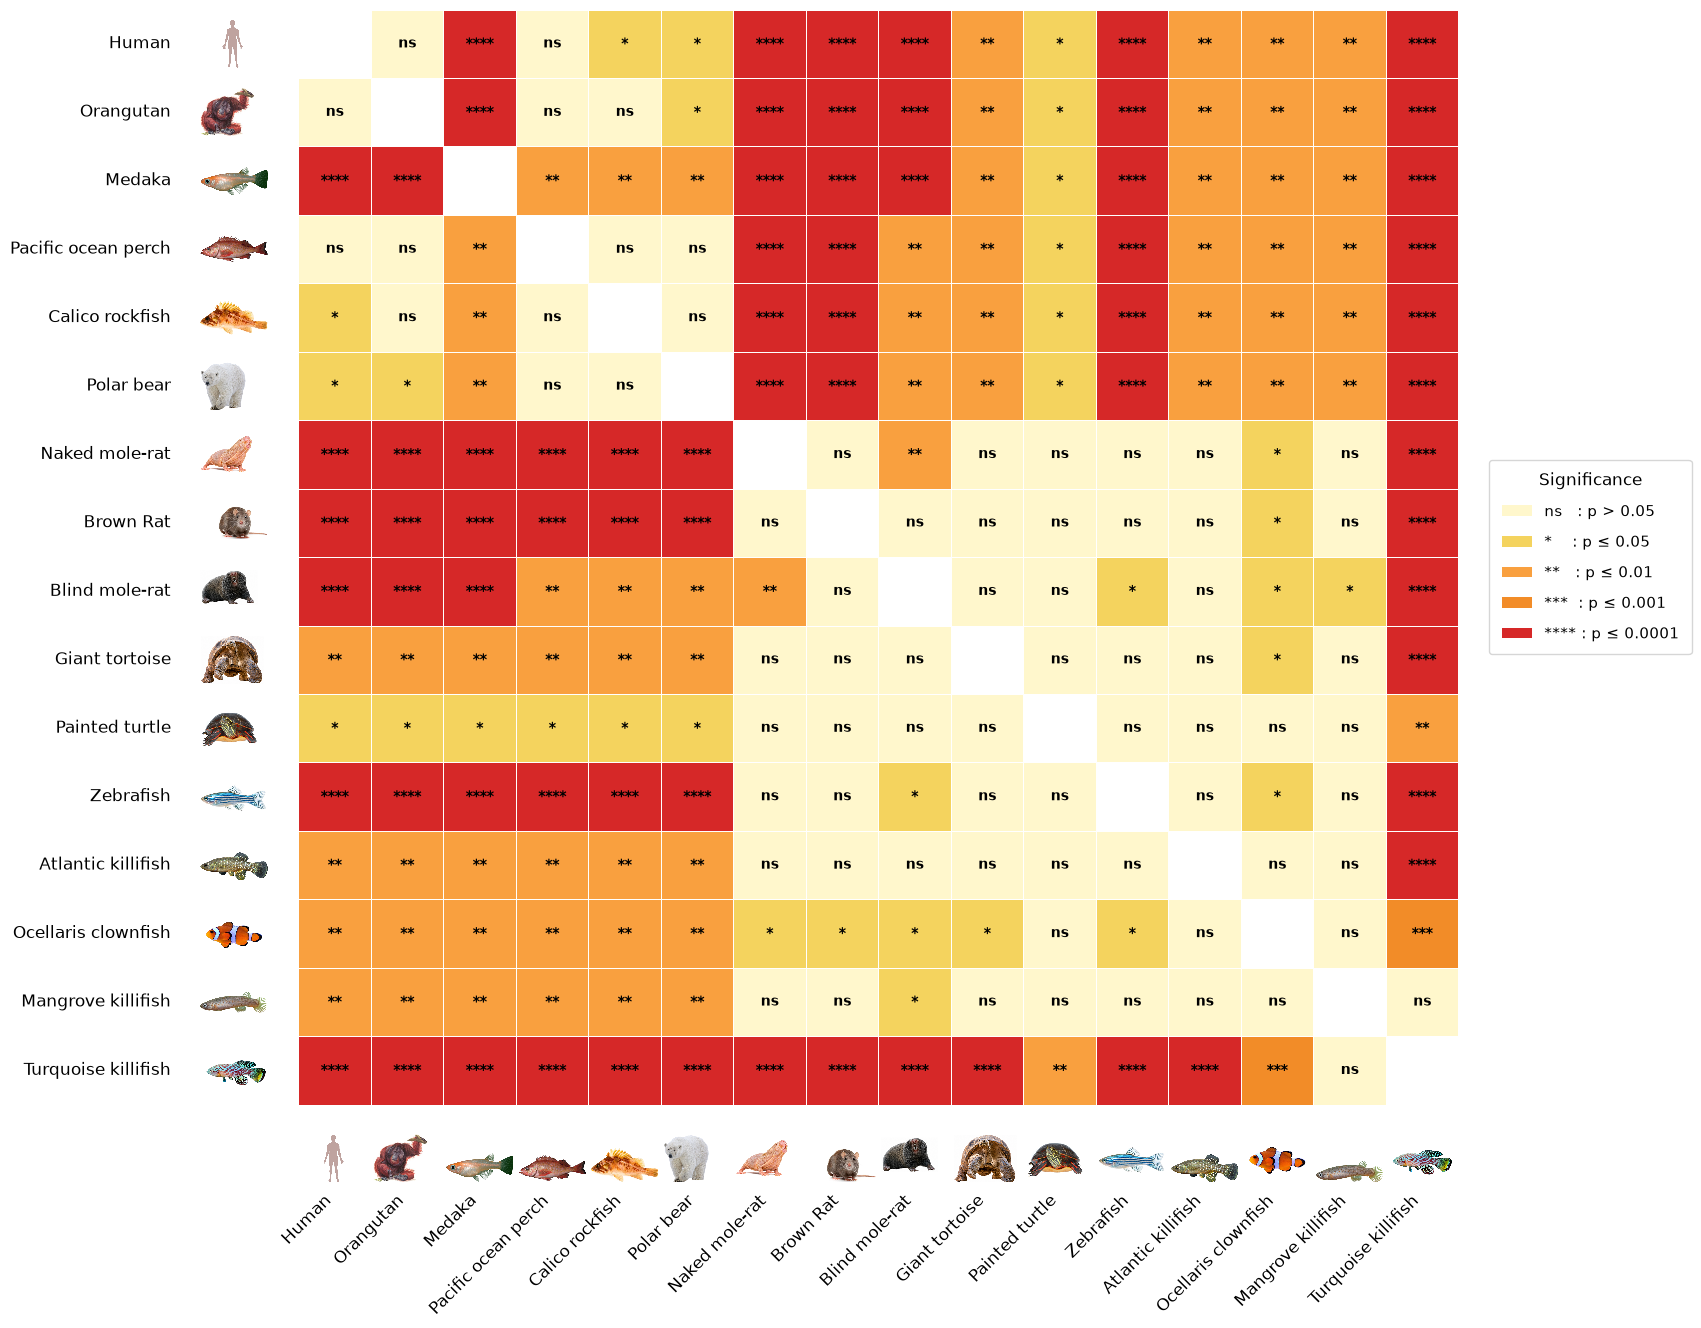

In [5]:
import pandas as pd
import numpy as np
import os
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


# -----------------------------
# Species names
# -----------------------------
species = [
    'Human',
    'Orangutan',
    'Medaka',
    'Pacific ocean perch',
    'Calico rockfish',
    'Polar bear',
    'Naked mole-rat',
    'Brown Rat',
    'Blind mole-rat',
    'Giant tortoise',
    'Painted turtle',
    'Zebrafish',
    'Atlantic killifish',
    'Ocellaris clownfish',
    'Mangrove killifish',
    'Turquoise killifish'
    
]
# -----------------------------
# Image map
# -----------------------------
img_map = {
    'Human': 'Hs1.png',
    'Naked mole-rat': 'Hg.png',
    'Brown Rat': 'Rn.png',
    'Blind mole-rat': 'Ng.png',
    'Giant tortoise': 'Ca.png',
    'Painted turtle': 'Cp.png',
    'Turquoise killifish': 'Nf.png',
    'Mangrove killifish': 'Km.png',
    'Medaka': 'OL.png',
    'Zebrafish': 'Dr.png',
    'Pacific ocean perch': 'Sa.png',
    'Calico rockfish': 'Sd.png',
    'Orangutan': 'PP.png',
    'Polar bear': 'Um.png',
    'Atlantic killifish': 'Fh.png',
    'Ocellaris clownfish': 'AO.png',
}

# -----------------------------
# Raw data
# -----------------------------
data = {
    'Human': [
        0.885168485, 0.977178604, 1.137652911, 0.788712865, 0.924289407,
        1.286997728, 1, 1.085802324, 0.993551932, 0.920645744,
        1.162521664, 0.881366644, 0.956111692, 0.770350483, 1.311285577,
        0.918363941, 1.078407324, 0.99318969, 0.928402986,0.923975131511224,0.963226295345482,1.11279857314329
    ],
    'Orangutan': [
        1.04910461181506, 1.03251068213007, 1.10355646212911
    ],
    'Medaka': [
        0.155781953, 0.071886647, 0.079883179, 0.179719331, 0.194920293,
        0.199848202, 0.323773628, 0.203701459, 0.156919083
    ],
    'Pacific ocean perch': [
        1.527294255, 1.56998693, 1.180725318
    ],
    'Calico rockfish': [
        1.536997496, 1.599853852, 1.232039143
    ],
    'Polar bear': [
        1.720848, 1.431409, 1.516269
    ],
    'Naked mole-rat': [
        5.410308026, 4.308915397, 4.360904451, 3.764026036, 3.566517619,
        3.228908902,3.729980388,4.625650351,3.790671107
    ],
    'Brown Rat': [
        3.86673005, 3.90648367, 3.877321542, 3.205099579, 3.415187684, 3.511652654
    ],
    'Blind mole-rat': [
        3.299877795, 3.359159736, 3.328270119
    ],
    'Giant tortoise': [
        3.407816728, 4.15369761, 4.672783978, 3.431409724
    ],
    'Painted turtle': [
        1.961968388, 5.480584799, 4.810126053, 4.3401917
    ],
    'Zebrafish': [
        2.706179445, 4.148308078, 3.415095274, 3.166771868, 3.631785099,
        3.614171094, 5.291312054, 4.861710409, 5.369103489, 4.599184349,
        3.535085341, 3.465246334, 2.939174565
    ],
    'Atlantic killifish': [
        4.813413, 4.15261, 4.014674
    ],
    'Ocellaris clownfish': [
        5.603966, 4.646591, 5.026026
    ],
    'Mangrove killifish': [
        4.141764376, 3.691818154, 3.141984537, 7.905521043, 7.30818862,
        7.579184879
    ],
    'Turquoise killifish': [
        5.943526361, 10.09940807, 11.50853339, 7.726554912, 9.240917361,
        4.494249511, 5.816512167, 7.787718618, 8.185712113, 11.5590207,
        6.437964995, 7.375363719, 6.591128992]

}

# -----------------------------
# Convert p-value to significance text
# -----------------------------
def p_to_stars(p):
    if pd.isna(p):
        return ""
    elif p <= 0.0001:
        return "****"
    elif p <= 0.001:
        return "***"
    elif p <= 0.01:
        return "**"
    elif p <= 0.05:
        return "*"
    else:
        return "ns"

# -----------------------------
# Pairwise Welch's t-test
# -----------------------------
df = pd.DataFrame({k: pd.Series(v) for k, v in data.items()})

pvals = pd.DataFrame(np.nan, index=species, columns=species)

for i, sp1 in enumerate(species):
    for j, sp2 in enumerate(species):
        if i < j:
            x = df[sp1].dropna().astype(float).values
            y = df[sp2].dropna().astype(float).values
            _, p = ttest_ind(x, y, equal_var=False, nan_policy='omit')
            pvals.loc[sp1, sp2] = p
            pvals.loc[sp2, sp1] = p
        elif i == j:
            pvals.loc[sp1, sp2] = 1.0

# -----------------------------
# Make annotation matrix
# -----------------------------
star_annot = pvals.apply(lambda col: col.map(p_to_stars))
for i in range(len(species)):
    star_annot.iloc[i, i] = ""

# -----------------------------
# Discrete colors for significance
# ns, *, **, ***, ****
# -----------------------------
sig_order = ["ns", "*", "**", "***", "****"]
sig_to_num = {s: i for i, s in enumerate(sig_order)}

heat_num = star_annot.replace(sig_to_num)
heat_num = heat_num.replace("", np.nan)

colors = [
    "#fff7cc",  # ns = light yellow
    "#f4d35e",  # *  = yellow
    "#f9a03f",  # ** = light orange
    "#f28c28",  # *** = orange
    "#d62828"   # **** = red
]
cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(-0.5, 5.5, 1), cmap.N)

# -----------------------------
# Plot heatmap
# -----------------------------
fig, ax = plt.subplots(figsize=(20, 15))

sns.heatmap(
    heat_num.astype(float),
    cmap=cmap,
    norm=norm,
    linewidths=0.5,
    linecolor='white',
    cbar=False,
    annot=star_annot,
    fmt='',
    annot_kws={'fontsize': 10, 'fontweight': 'bold', 'color': 'black'},
    ax=ax
)

# set tick positions
n = len(species)
ax.set_xticks(np.arange(n) + 0.5)
ax.set_yticks(np.arange(n) + 0.5)

# hide default tick labels
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.tick_params(length=0)

# -----------------------------
# Add image + species names on X axis
# -----------------------------
for i, sp in enumerate(species):
    img_file = img_map.get(sp)

    if img_file and os.path.exists(img_file):
        img = Image.open(img_file).convert("RGBA")
        imagebox = OffsetImage(img, zoom=0.05)

        ab = AnnotationBbox(
            imagebox,
            (i + 0.5, 0),
            xybox=(0, -56),
            xycoords=('data', 'axes fraction'),
            boxcoords="offset points",
            frameon=False,
            box_alignment=(0.5, 0)
        )
        ax.add_artist(ab)

    ax.text(
        i + 0.5, -0.08, sp,
        transform=ax.get_xaxis_transform(),
        ha='right',
        va='top',
        rotation=45,
        fontsize=12
    )

# -----------------------------
# Add image + species names on Y axis
# -----------------------------
for i, sp in enumerate(species):
    img_file = img_map.get(sp)

    if img_file and os.path.exists(img_file):
        img = Image.open(img_file).convert("RGBA")
        imagebox = OffsetImage(img, zoom=0.05)

        ab = AnnotationBbox(
            imagebox,
            (0, i + 0.5),
            xybox=(-22, 0),
            xycoords=('axes fraction', 'data'),
            boxcoords="offset points",
            frameon=False,
            box_alignment=(1, 0.5)
        )
        ax.add_artist(ab)

    ax.text(
        -0.11, i + 0.5, sp,
        transform=ax.get_yaxis_transform(),
        ha='right',
        va='center',
        fontsize=12
    )

# -----------------------------
# Custom legend for significance colors
# -----------------------------
legend_elements = [
    Patch(facecolor="#fff7cc", edgecolor='none', label="ns   : p > 0.05"),
    Patch(facecolor="#f4d35e", edgecolor='none', label="*    : p ≤ 0.05"),
    Patch(facecolor="#f9a03f", edgecolor='none', label="**   : p ≤ 0.01"),
    Patch(facecolor="#f28c28", edgecolor='none', label="***  : p ≤ 0.001"),
    Patch(facecolor="#d62828", edgecolor='none', label="**** : p ≤ 0.0001")
]

ax.legend(
    handles=legend_elements,
    title="Significance",
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    frameon=True,
    borderpad=0.8,
    labelspacing=1.0,
    fontsize=11,
    title_fontsize=12
)

plt.subplots_adjust(left=0.28, bottom=0.25, right=0.86, top=0.98)

plt.show()
fig.savefig("statistic.png", dpi=600, bbox_inches="tight", pad_inches=0.1)